# 04, modélisation

Phase 4 de CRISP-DM. Ce notebook note les trois stratégies retenues sur l'eau, le revenu et le sol, les classe pour chaque priorité de l'agriculteur, puis teste la stabilité du classement face à une pluie réduite de 20 % et à un début de saison retardé de deux semaines. Il appelle `moteur/criteres.py` et `moteur/rotations.py` sans calcul propre.

Aucun rendement n'est prédit. Les scores sont des comparaisons argumentées, à règles visibles, et non une solution optimale.

In [1]:
import sys
from pathlib import Path

RACINE = Path.cwd().parent
sys.path.insert(0, str(RACINE))

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from moteur.criteres import (CRITERES, INDICATEURS, POIDS_PAR_PRIORITE, SCENARIOS, contextes_du_lieu, sensibilite,
                             tableau_evaluations, tableau_scenarios, tableau_scores)
from moteur.lieux import LIEUX
from moteur.rotations import STRATEGIES

pd.set_option("display.precision", 3)
noms = {identifiant: lieu["nom"] for identifiant, lieu in LIEUX.items()}
contextes = {identifiant: contextes_du_lieu(identifiant) for identifiant in LIEUX}

## 1. Règles de notation

Chaque critère est une liste d'indicateurs, et son score de 0 à 5 est la moyenne de ses indicateurs disponibles. Les règles sont décrites en tête de `moteur/criteres.py`.

In [2]:
display(pd.DataFrame([{"critère": c, "indicateurs": ", ".join(f.__name__ for f in INDICATEURS[c])} for c in CRITERES]))
display(pd.DataFrame({p: dict(poids) for p, poids in POIDS_PAR_PRIORITE.items()}).T)
pd.DataFrame(SCENARIOS).T

,critère,indicateurs
0,eau,"couverture_du_besoin, besoin_en_eau"
1,revenu,part_de_culture_de_rente
2,sol,part_de_legumineuses


,eau,revenu,sol
eau,0.6,0.2,0.2
revenu,0.2,0.6,0.2
sol,0.2,0.2,0.6


,facteur_pluie,retard_jours
reference,1.0,0.0
pluie_moins_20_pourcent,0.8,0.0
debut_retarde_de_14_jours,1.0,14.0


**Constat.** L'eau a deux indicateurs, la couverture du besoin, part des années où la pluie du cycle couvre le besoin en eau de la culture, et le besoin en eau, placé entre la culture comparée la plus économe et la plus exigeante. Le sol a un indicateur, la part des années en légumineuse, et le revenu un, la part des années en coton. Chaque priorité donne un poids de 0,6 à son critère et de 0,2 aux deux autres.

**Analyse.** Les deux indicateurs d'eau sont de niveau `calcule`, tirés des données NASA et de FAO-56. Les indicateurs de sol et de revenu sont de niveau `hypothese`. Ils reposent sur des sources lues hors du Poro, Yusuf et collègues au Nigeria et Cattan et collègues au Burkina Faso pour le sol, Guenot et Huchet-Bourdon au Burkina Faso pour le revenu, et le revenu reste qualitatif faute de prix sourcés. Les poids et le passage d'une valeur à un score sont des choix de l'équipe, pas des résultats.

**Décision.** Ces règles servent de version de départ, à valider par l'équipe et si possible par un agronome. Un indicateur tiré de SMAP ou de MODIS s'ajoutera à la liste de son critère sans changer le reste.

## 2. Évaluations détaillées, scénario de référence

In [3]:
for identifiant, contexte in contextes.items():
    print(noms[identifiant])
    display(tableau_evaluations(STRATEGIES, contexte["reference"]))

Korhogo


,strategie,critere,indicateur,valeur,bas,haut,unite,score,niveau,source
0,coton_mais,eau,couverture_du_besoin,0.980,0.960,1.000,part des années,4.900,calcule,"FAO56_T11_T12, IMERG, POWER"
1,coton_mais,eau,besoin_en_eau,600.244,481.661,718.827,mm par saison,2.090,calcule,"FAO56_T11_T12, POWER"
2,coton_mais,revenu,part_de_culture_de_rente,0.500,NaN,NaN,part des années,2.500,hypothese,GUENOT2014
3,coton_mais,sol,part_de_legumineuses,0.000,NaN,NaN,part des années,0.000,hypothese,"YUSUF2009, CATTAN2001"
4,coton_niebe_mais,eau,couverture_du_besoin,0.960,0.920,1.000,part des années,4.800,calcule,"FAO56_T11_T12, IMERG, POWER"
5,coton_niebe_mais,eau,besoin_en_eau,535.209,405.138,718.827,mm par saison,2.940,calcule,"FAO56_T11_T12, POWER"
6,coton_niebe_mais,revenu,part_de_culture_de_rente,0.333,NaN,NaN,part des années,1.667,hypothese,GUENOT2014
7,coton_niebe_mais,sol,part_de_legumineuses,0.333,NaN,NaN,part des années,1.667,hypothese,"YUSUF2009, CATTAN2001"
8,sorgho_niebe,eau,couverture_du_besoin,0.960,0.920,1.000,part des années,4.800,calcule,"FAO56_T11_T12, IMERG, POWER"
9,sorgho_niebe,eau,besoin_en_eau,429.139,405.138,453.140,mm par saison,4.326,calcule,"FAO56_T11_T12, POWER"


Bouaké


,strategie,critere,indicateur,valeur,bas,haut,unite,score,niveau,source
0,coton_mais,eau,couverture_du_besoin,0.920,0.880,0.960,part des années,4.600,calcule,"FAO56_T11_T12, IMERG, POWER"
1,coton_mais,eau,besoin_en_eau,511.424,414.953,607.895,mm par saison,2.194,calcule,"FAO56_T11_T12, POWER"
2,coton_mais,revenu,part_de_culture_de_rente,0.500,NaN,NaN,part des années,2.500,hypothese,GUENOT2014
3,coton_mais,sol,part_de_legumineuses,0.000,NaN,NaN,part des années,0.000,hypothese,"YUSUF2009, CATTAN2001"
4,coton_niebe_mais,eau,couverture_du_besoin,0.907,0.880,0.960,part des années,4.533,calcule,"FAO56_T11_T12, IMERG, POWER"
5,coton_niebe_mais,eau,besoin_en_eau,456.568,346.857,607.895,mm par saison,3.013,calcule,"FAO56_T11_T12, POWER"
6,coton_niebe_mais,revenu,part_de_culture_de_rente,0.333,NaN,NaN,part des années,1.667,hypothese,GUENOT2014
7,coton_niebe_mais,sol,part_de_legumineuses,0.333,NaN,NaN,part des années,1.667,hypothese,"YUSUF2009, CATTAN2001"
8,sorgho_niebe,eau,couverture_du_besoin,0.920,0.880,0.960,part des années,4.600,calcule,"FAO56_T11_T12, IMERG, POWER"
9,sorgho_niebe,eau,besoin_en_eau,368.567,346.857,390.276,mm par saison,4.325,calcule,"FAO56_T11_T12, POWER"


**Constat.** La pluie du cycle couvre le besoin en eau une part de 0,96 à 0,98 des années à Korhogo et de 0,907 à 0,92 à Bouaké, selon la stratégie. Le besoin moyen par saison vaut 600,244 mm pour coton puis maïs à Korhogo, 535,209 mm pour coton, niébé puis maïs et 429,139 mm pour sorgho puis niébé. Coton puis maïs n'a aucune légumineuse et un coton une année sur deux, sorgho puis niébé une légumineuse une année sur deux et aucun coton.

**Analyse.** La couverture du besoin distingue peu les stratégies, parce que la pluie totale du cycle dépasse le besoin presque chaque année. Le besoin en eau les distingue davantage, mais il dépend surtout de la durée des cycles, le coton durant 195 jours. Les plages de chaque valeur, entre la culture la moins et la plus favorable de la rotation, figurent dans les colonnes bas et haut.

**Décision.** Les deux indicateurs d'eau sont gardés ensemble, l'un pour le risque de manque, l'autre pour l'économie d'eau.

## 3. Scores et classement pour chaque priorité

Korhogo, priorité eau


,eau,revenu,sol,actuelle,note,rang
sorgho_niebe,4.563,0.000,2.500,False,3.238,1
coton_niebe_mais,3.870,1.667,1.667,False,2.989,2
coton_mais,3.495,2.500,0.000,True,2.597,3


Korhogo, priorité revenu


,eau,revenu,sol,actuelle,note,rang
coton_mais,3.495,2.500,0.000,True,2.199,1
coton_niebe_mais,3.870,1.667,1.667,False,2.107,2
sorgho_niebe,4.563,0.000,2.500,False,1.413,3


Korhogo, priorité sol


,eau,revenu,sol,actuelle,note,rang
sorgho_niebe,4.563,0.000,2.500,False,2.413,1
coton_niebe_mais,3.870,1.667,1.667,False,2.107,2
coton_mais,3.495,2.500,0.000,True,1.199,3


... (2 outputs left out)

Bouaké, priorité revenu


,eau,revenu,sol,actuelle,note,rang
coton_mais,3.397,2.500,0.000,True,2.179,1
coton_niebe_mais,3.773,1.667,1.667,False,2.088,2
sorgho_niebe,4.463,0.000,2.500,False,1.393,3


Bouaké, priorité sol


,eau,revenu,sol,actuelle,note,rang
sorgho_niebe,4.463,0.000,2.500,False,2.393,1
coton_niebe_mais,3.773,1.667,1.667,False,2.088,2
coton_mais,3.397,2.500,0.000,True,1.179,3


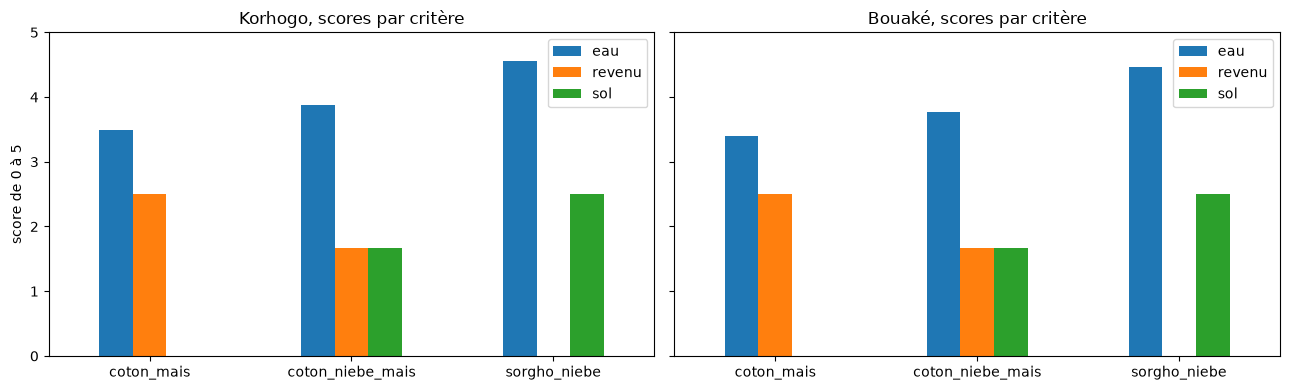

In [4]:
for identifiant, contexte in contextes.items():
    for priorite, poids in POIDS_PAR_PRIORITE.items():
        print(f"{noms[identifiant]}, priorité {priorite}")
        display(tableau_scores(STRATEGIES, contexte["reference"], poids))

figure, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for axe, (identifiant, contexte) in zip(axes, contextes.items()):
    table = tableau_scores(STRATEGIES, contexte["reference"], POIDS_PAR_PRIORITE["eau"]).sort_index()
    table[list(CRITERES)].plot.bar(ax=axe, rot=0)
    axe.set(title=f"{noms[identifiant]}, scores par critère", ylabel="score de 0 à 5", ylim=(0, 5))
plt.tight_layout()
plt.show()

**Constat.** Dans les deux villes, sorgho puis niébé arrive premier pour les priorités eau et sol, avec une note de 3,238 à Korhogo pour la priorité eau, et coton puis maïs arrive premier pour la priorité revenu, avec 2,199. Coton, niébé puis maïs est deuxième pour les trois priorités. Korhogo et Bouaké reçoivent le même classement.

**Analyse.** Le classement suit la composition des rotations plus que le climat. Les scores de sol et de revenu ne dépendent pas du lieu, et l'écart de couverture entre les deux villes, de 0,98 contre 0,92 pour coton puis maïs, ne suffit pas à changer l'ordre. Le critère 3 du cadrage demande que l'écart entre les villes suive les données ou que son absence soit expliquée. C'est ici une absence expliquée, qui montre aussi que les données NASA pèsent peu dans le classement actuel.

**Décision.** Ce résultat est signalé tel quel. Les indicateurs de surface tirés de SMAP et de MODIS, propres à chaque lieu, sont la voie prévue pour que les données d'observation pèsent davantage.

## 4. Sensibilité à une pluie réduite et à un début de saison retardé

Dans le scénario de pluie réduite, toute la pluie est multipliée par 0,8, début de saison compris. Dans le scénario de début retardé, chaque cycle commence 14 jours après le début de saison de l'année.

In [5]:
for identifiant, contexte in contextes.items():
    print(noms[identifiant])
    valeurs = tableau_scenarios(STRATEGIES, contexte)
    display(valeurs.loc[valeurs.index.get_level_values("indicateur").isin(["couverture_du_besoin", "besoin_en_eau"])])
    for priorite, poids in POIDS_PAR_PRIORITE.items():
        rangs, stable, changeants = sensibilite(STRATEGIES, contexte, poids)
        print(f"priorité {priorite}, classement stable {stable}, scénarios qui le changent {changeants}")
        display(rangs)

Korhogo


reference  pluie_moins_20_pourcent  \
strategie        indicateur                                                 
coton_mais       couverture_du_besoin      0.980                    0.740   
                 besoin_en_eau           600.244                  576.138   
coton_niebe_mais couverture_du_besoin      0.960                    0.707   
                 besoin_en_eau           535.209                  509.548   
sorgho_niebe     couverture_du_besoin      0.960                    0.780   
                 besoin_en_eau           429.139                  399.698   

                                       debut_retarde_de_14_jours  
strategie        indicateur                                       
coton_mais       couverture_du_besoin                      1.000  
                 besoin_en_eau                           580.016  
coton_niebe_mais couverture_du_besoin                      1.000  
                 besoin_en_eau                           512.544  
sorgho_niebe     couverture_du_besoin                      1.000  
                 besoin_en_eau                           402.940

priorité eau, classement stable True, scénarios qui le changent []


,reference,pluie_moins_20_pourcent,debut_retarde_de_14_jours
sorgho_niebe,1,1,1
coton_niebe_mais,2,2,2
coton_mais,3,3,3


priorité revenu, classement stable True, scénarios qui le changent []


,reference,pluie_moins_20_pourcent,debut_retarde_de_14_jours
coton_mais,1,1,1
coton_niebe_mais,2,2,2
sorgho_niebe,3,3,3


... (6 outputs left out)

priorité revenu, classement stable True, scénarios qui le changent []


,reference,pluie_moins_20_pourcent,debut_retarde_de_14_jours
coton_mais,1,1,1
coton_niebe_mais,2,2,2
sorgho_niebe,3,3,3


priorité sol, classement stable True, scénarios qui le changent []


,reference,pluie_moins_20_pourcent,debut_retarde_de_14_jours
sorgho_niebe,1,1,1
coton_niebe_mais,2,2,2
coton_mais,3,3,3


**Constat.** Une pluie réduite de 20 % fait tomber la couverture du besoin de 0,98 à 0,74 pour coton puis maïs à Korhogo, et de 0,92 à 0,56 à Bouaké. Un début retardé de 14 jours la porte à 1,0 à Korhogo, où les cycles glissent vers les mois les plus pluvieux, mais la fait baisser à Bouaké, de 0,92 à 0,9 pour coton puis maïs. Pour les trois priorités et dans les deux villes, le classement reste le même dans les deux scénarios.

**Analyse.** Les scénarios touchent fortement l'eau, mais presque autant chaque stratégie, si bien que l'ordre ne change pas. Les deux villes répondent en sens contraire à un début retardé, ce qui est une différence locale réelle, visible dans les valeurs mais non dans le classement.

**Décision.** Le classement est déclaré stable face à ces deux scénarios, et l'outil le dit en montrant aussi la baisse de la couverture du besoin, pour que l'agriculteur voie le risque d'une saison sèche quelle que soit sa rotation.

## 5. Critères à venir

**Constat.** Les extractions AppEEARS de MCD12Q1 sont soumises, et MOD13Q1, SMAP et SRTM suivront sur les points cultivés.

**Analyse.** L'humidité du sol au début de saison mesurée par SMAP, les périodes de sol nu tirées du NDVI de MODIS et la pente de SRTM donneraient des indicateurs propres à chaque lieu, aujourd'hui absents.

**Décision.** Chacun deviendra une fonction inscrite dans `INDICATEURS`, alimentée par le champ `surfaces` du contexte, et ce notebook sera réexécuté.